Setting up PySpark environment

In [1]:
%pip install -q pyspark

In [2]:
from pyspark.sql import SparkSession
import pyspark

spark = (
    SparkSession.builder
    .appName("AdaptiveSkewAwareAggregation")
    .master("local[*]")
    .config("spark.sql.shuffle.partitions", "4")
    .getOrCreate()
)

print("PySpark version:", pyspark.__version__)
print("Spark version:", spark.version)
print("Spark master:", spark.sparkContext.master)
print("Default parallelism:", spark.sparkContext.defaultParallelism)

PySpark version: 4.0.5
Spark version: 4.0.5
Spark master: local[*]
Default parallelism: 2


In [3]:
data = [
    ("Amazon", 100),
    ("Google", 200),
    ("Amazon", 150),
    ("Microsoft", 300),
    ("Amazon", 250),
    ("Google", 100),
    ("Amazon", 400)
]

df = spark.createDataFrame(data, ["company", "amount"])

df.show()

+---------+------+
|  company|amount|
+---------+------+
|   Amazon|   100|
|   Google|   200|
|   Amazon|   150|
|Microsoft|   300|
|   Amazon|   250|
|   Google|   100|
|   Amazon|   400|
+---------+------+



In [4]:
result = df.groupBy("company").count()

result.show()

+---------+-----+
|  company|count|
+---------+-----+
|   Google|    2|
|   Amazon|    4|
|Microsoft|    1|
+---------+-----+



In [5]:
actual = {
    row["company"]: row["count"]
    for row in result.collect()
}

expected = {
    "Amazon": 4,
    "Google": 2,
    "Microsoft": 1
}

assert actual == expected, "Aggregation results are incorrect!"

print("SUCCESS: PySpark environment and aggregation verified.")

SUCCESS: PySpark environment and aggregation verified.


Synthetic Dataset Generator

In [6]:
from pyspark.sql import functions as F

def generate_dataset(
    spark,
    num_records,
    num_keys=100,
    distribution="uniform",
    skew_level=0.8,
    num_partitions=2,
    seed=42
):
    """
    Generate a synthetic PySpark DataFrame.

    Parameters:
        spark: Active SparkSession
        num_records: Total number of records
        num_keys: Number of possible unique keys
        distribution: 'uniform' or 'skewed'
        skew_level: Probability of selecting the hot key (key_0)
        num_partitions: Number of initial Spark partitions
        seed: Random seed for reproducibility

    Returns:
        PySpark DataFrame with columns (key, value)
    """

    if num_records <= 0:
        raise ValueError("num_records must be positive")

    if num_keys < 2:
        raise ValueError("num_keys must be at least 2")

    if num_partitions <= 0:
        raise ValueError("num_partitions must be positive")

    if distribution not in ("uniform", "skewed"):
        raise ValueError("distribution must be 'uniform' or 'skewed'")

    if not 0 <= skew_level <= 1:
        raise ValueError("skew_level must be between 0 and 1")

    # Generate distributed record IDs
    df = spark.range(
        0,
        num_records,
        numPartitions=num_partitions
    )

    if distribution == "uniform":

        # Assign each record a random key
        df = df.withColumn(
            "key_id",
            (F.rand(seed) * num_keys).cast("int")
        )

    else:

        # Generate independent random values
        df = df.withColumn(
            "random_hot",
            F.rand(seed)
        ).withColumn(
            "random_other",
            F.rand(seed + 1)
        )

        # With probability skew_level, choose key_0
        # Otherwise choose one of the remaining keys
        df = df.withColumn(
            "key_id",
            F.when(
                F.col("random_hot") < skew_level,
                F.lit(0)
            ).otherwise(
                (F.col("random_other") * (num_keys - 1)).cast("int") + 1
            )
        )

    # Create final key and value columns
    df = df.select(
        F.concat(F.lit("key_"), F.col("key_id")).alias("key"),
        F.lit(1).alias("value")
    )

    return df

In [7]:
uniform_df = generate_dataset(
    spark,
    num_records=10000,
    num_keys=10,
    distribution="uniform",
    num_partitions=2
)

uniform_df.show(10)

uniform_df.groupBy("key") \
    .count() \
    .orderBy("key") \
    .show()

+-----+-----+
|  key|value|
+-----+-----+
|key_6|    1|
|key_5|    1|
|key_8|    1|
|key_2|    1|
|key_6|    1|
|key_5|    1|
|key_9|    1|
|key_0|    1|
|key_9|    1|
|key_7|    1|
+-----+-----+
only showing top 10 rows
+-----+-----+
|  key|count|
+-----+-----+
|key_0| 1018|
|key_1| 1035|
|key_2|  992|
|key_3|  985|
|key_4| 1044|
|key_5| 1049|
|key_6|  984|
|key_7|  957|
|key_8|  972|
|key_9|  964|
+-----+-----+



Generating skewed dataset - key-frequency skew

In [8]:
skewed_df = generate_dataset(
    spark,
    num_records=10000,
    num_keys=10,
    distribution="skewed",
    skew_level=0.8,
    num_partitions=2
)

skewed_df.groupBy("key") \
    .count() \
    .orderBy(F.desc("count")) \
    .show()

+-----+-----+
|  key|count|
+-----+-----+
|key_0| 8064|
|key_8|  230|
|key_2|  229|
|key_5|  228|
|key_3|  223|
|key_7|  217|
|key_4|  207|
|key_9|  207|
|key_1|  200|
|key_6|  195|
+-----+-----+



Visualization

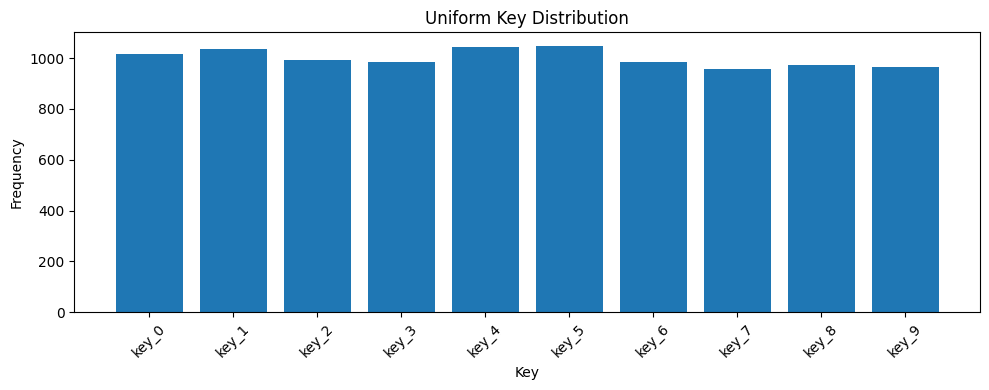

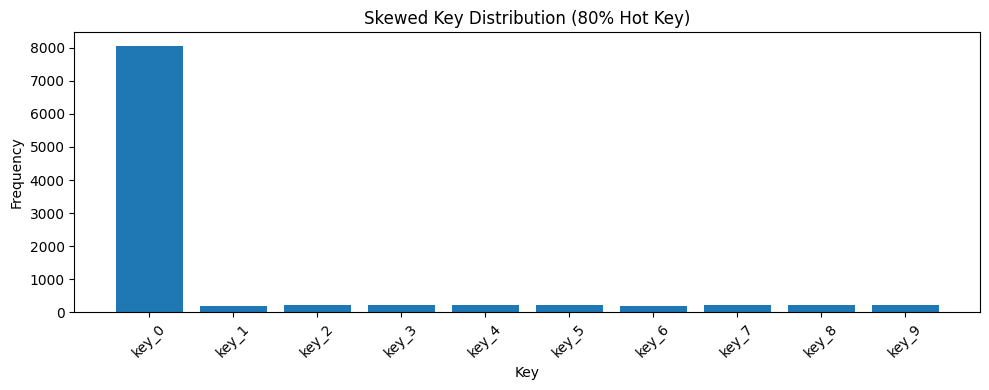

In [9]:
import matplotlib.pyplot as plt

def plot_key_distribution(df, title):
    counts = (
        df.groupBy("key")
          .count()
          .orderBy("key")
          .collect()
    )

    keys = [row["key"] for row in counts]
    frequencies = [row["count"] for row in counts]

    plt.figure(figsize=(10, 4))
    plt.bar(keys, frequencies)

    plt.xlabel("Key")
    plt.ylabel("Frequency")
    plt.title(title)
    plt.xticks(rotation=45)
    plt.tight_layout()
    plt.show()


plot_key_distribution(
    uniform_df,
    "Uniform Key Distribution"
)

plot_key_distribution(
    skewed_df,
    "Skewed Key Distribution (80% Hot Key)"
)

Baseline key-based aggregation approach using standard Apache Spark operations